<a href="https://colab.research.google.com/github/AhmadKevin000/machineLearning/blob/main/week11_prak5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 5 — Klasifikasi Citra Siang dan Malam


## Langkah 0 - Import Library

**Soal:** Import seluruh library yang dibutuhkan (Pathlib, Matplotlib, OpenCV, NumPy, Pandas), kemudian definisikan lokasi folder gambar training dan test.

In [66]:
# Import Required Libraries
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [67]:
# Image directories
train_dir = "images/training/"
test_dir = "images/test/"

## Langkah 1 - Load Data dan Visualisasikan

**Soal:** Buat fungsi `load_dataset` untuk membuat daftar seluruh path gambar beserta labelnya, kemudian load gambar training dan lakukan pengecekan data pertama serta ukuran gambar secara acak.

In [68]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        label = str(dir).split('/')[-1]
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if not img is None:
                img_list.append((img, label))

    return img_list

In [69]:
# Load training data
train_img = load_dataset(train_dir)

In [70]:
train_img[0]

(array([[[79, 81, 70],
         [76, 78, 67],
         [72, 74, 63],
         ...,
         [63, 61, 62],
         [71, 69, 70],
         [77, 75, 76]],
 
        [[78, 80, 69],
         [75, 77, 66],
         [71, 73, 62],
         ...,
         [49, 47, 48],
         [54, 52, 53],
         [57, 55, 56]],
 
        [[77, 79, 68],
         [73, 75, 64],
         [69, 71, 60],
         ...,
         [44, 42, 43],
         [46, 44, 45],
         [47, 45, 46]],
 
        ...,
 
        [[94, 85, 78],
         [94, 85, 78],
         [93, 84, 77],
         ...,
         [68, 55, 49],
         [68, 55, 49],
         [69, 56, 50]],
 
        [[94, 85, 78],
         [93, 84, 77],
         [93, 84, 77],
         ...,
         [66, 55, 49],
         [66, 55, 49],
         [66, 55, 49]],
 
        [[93, 84, 77],
         [93, 84, 77],
         [93, 84, 77],
         ...,
         [66, 55, 49],
         [66, 55, 49],
         [66, 55, 49]]], shape=(700, 1280, 3), dtype=uint8),
 'night')

In [71]:
# Random size checking
pick_random = np.random.randint(0, len(train_img))

# Check img size
print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 15
(593, 800, 3)


**Soal:** Buat fungsi `random_img_viz` untuk menampilkan gambar secara acak beserta shape dan labelnya, lalu lakukan visualisasi gambar training secara acak.

In [72]:
# Function to Visualize
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    label_str = 'day' if label == 1 else 'night'

    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Shape	: (372, 640, 3)
Label	: night


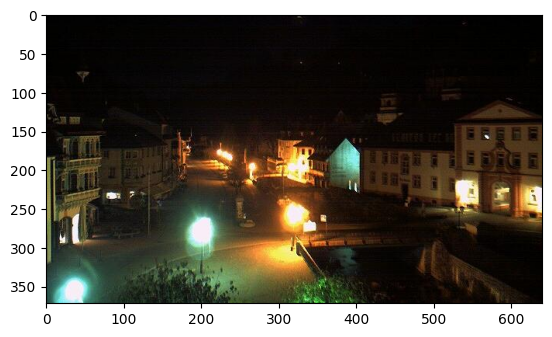

Shape	: (469, 640, 3)
Label	: day


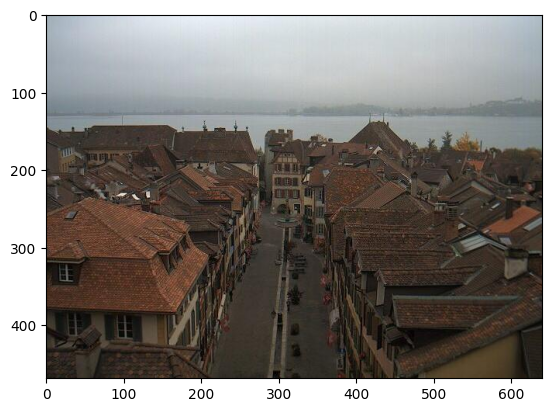

In [73]:
random_img_viz(train_img)

## Langkah 3 - Pra Pengolahan Data

**Soal:** Buat fungsi untuk standardisasi ukuran gambar (w: 1100, h: 600), encoding label (day = 1, night = 0), dan fungsi `preprocess` yang melakukan keduanya sekaligus. Kemudian lakukan pra pengolahan pada data training dan cek ukuran gambar hasilnya.

WARNING! Atribut `shape` menampilkan baris (height) x kolom (width).

In [74]:
def standarized_input(image):
    # resize to w: 1100, h:600
    std_img = cv2.resize(image, (1100,600))

    return std_img

In [75]:
def label_encoder(label):
    # Encode the label
    # day as 1; night as 0
    num_val = 0

    if(label == 'day'):
        num_val = 1

    return num_val

In [76]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standarized the image
        std_img = standarized_input(image)

        # Create the label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [77]:
train_std_img_list = preprocess(train_img)

In [78]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 59
(600, 1100, 3)
Image 10
(600, 1100, 3)


Shape	: (600, 1100, 3)
Label	: 0


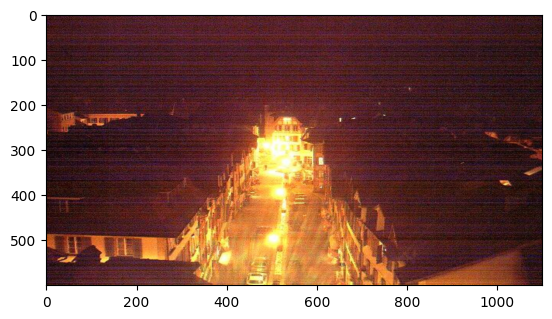

Shape	: (600, 1100, 3)
Label	: 0


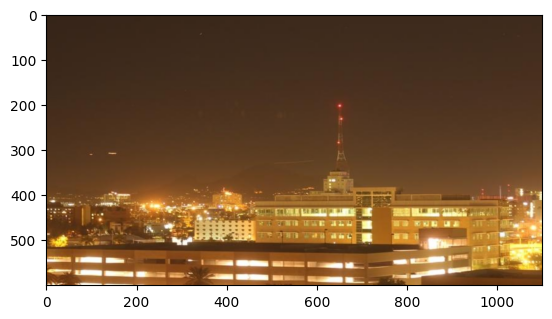

In [79]:
random_img_viz(train_std_img_list)

## Langkah 4 - Ekstraksi Fitur

**Soal:** Jelaskan mengapa ruang warna diubah dari RGB menjadi HSV sebelum menghitung fitur rata-rata kecerahan, kemudian buat fungsi `avg_brightness` dan cek nilainya pada gambar acak.

**Jawaban:** Tingkat kecerahan (brightness) lebih mudah didapatkan dari HSV berdasarkan nilai channel V (Value).

In [80]:
def avg_brightness(image):
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    sum_brightness = np.sum(img_hsv[:,:,2])
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 171
Avg Brighness: 126.7162


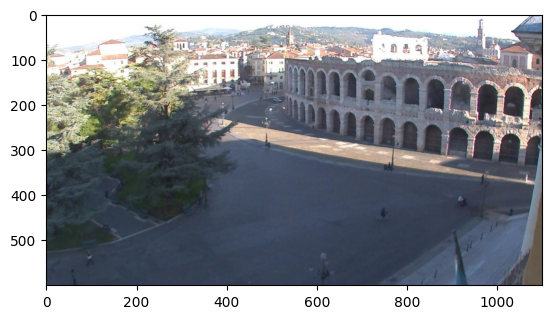

Image 166
Avg Brighness: 107.5791


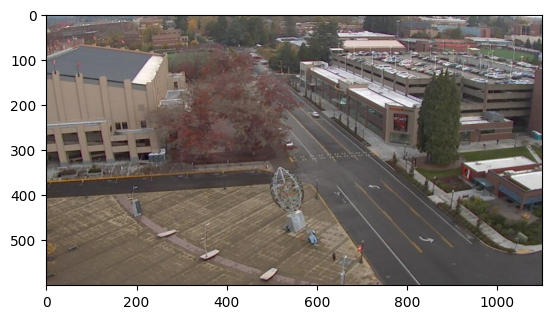

In [81]:
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brighness: {avg_img:.4f}')
plt.imshow(feature_img)

## Langkah 5 - Klasifikasi dengan Metode Threshold

**Soal:** Buat fungsi `predict_label` yang mengklasifikasikan gambar berdasarkan nilai ambang batas (threshold) rata-rata kecerahan, lalu cek prediksinya pada gambar acak data training dengan threshold = 120.

In [82]:
def predict_label(img, threshold):
    avg = avg_brightness(img)
    pred = 0

    if avg > threshold:
        pred = 1

    return pred

Image 19
Actual label: 0
Predicted label: 0


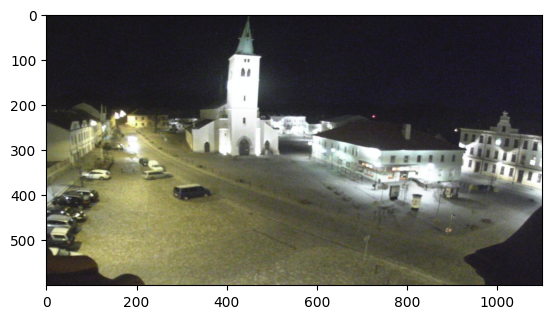

Image 100
Actual label: 0
Predicted label: 0


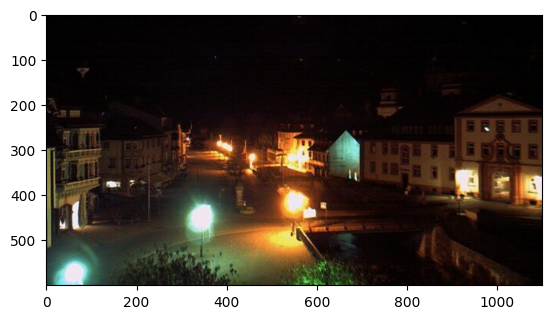

In [83]:
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])

## Langkah 6 - Evaluasi Manual

**Soal:** Buat fungsi `evaluate` untuk menghitung akurasi model dengan membandingkan label prediksi dan ground truth, lalu evaluasi pada data training (threshold = 120) dan data testing.

In [84]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        img = file[0]
        label = file[1]

        pred_label = predict_label(img, threshold)

        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [85]:
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417
Accuracy: 0.8417


In [86]:
test_img = load_dataset(test_dir)

test_std_img_list = preprocess(test_img)

evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688
Accuracy: 0.8688


**Analisis:** Coba ubah nilai ambang batas (threshold) dan amati perubahan hasilnya.

**Klasifikasi dengan SVM:** Metode threshold mungkin tidak efektif karena kita harus menentukan nilai threshold dengan tepat. Selanjutnya kita gunakan model SVM; seluruh langkah serupa, hanya langkah ke-4 yang diubah.

## Langkah 4 Alternatif - Membuat Feature Vectors

**Soal:** Buat fungsi `extract_avg_bright_feature` yang menabulasi seluruh nilai rata-rata kecerahan dan labelnya dalam bentuk tabel Pandas, lalu jalankan pada data training dan testing.

In [87]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]

        avg_list.append(img_avg)
        labels.append(img_label)

    data = np.column_stack((avg_list, labels))
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

In [88]:
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,99.043562,0.0
1,114.884670,0.0
2,25.715848,0.0
3,108.988659,0.0
4,26.946276,0.0


Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,99.043562,0.0
1,114.884670,0.0
2,25.715848,0.0
3,108.988659,0.0
4,26.946276,0.0


In [89]:
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,90.797277,0.0
1,82.955830,0.0
2,13.228938,0.0
3,26.318068,0.0
4,54.137088,0.0


Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,90.797277,0.0
1,82.955830,0.0
2,13.228938,0.0
3,26.318068,0.0
4,54.137088,0.0


## Langkah 5 - Buat Model SVM

**Soal:** Buat model SVM dengan kernel RBF (default) menggunakan scikit-learn, lalu latih dengan data training hasil ekstraksi fitur.

In [90]:
from sklearn.svm import SVC

X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
y_train = train_avg_img.iloc[:,1]
X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
y_test = test_avg_img.iloc[:,1]

model = SVC()
model.fit(X_train, y_train)

SVC()

SVC()

## Langkah 6 - Evaluasi

**Soal:** Evaluasi model SVM pada data training dan testing menggunakan `accuracy_score`, kemudian bandingkan hasilnya dengan metode threshold.

In [91]:
from sklearn.metrics import accuracy_score

y_train_pred = model.predict(X_train)

acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = model.predict(X_test)

acc_test = accuracy_score(y_test, y_test_pred)

print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9
Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


**Analisis:** Model SVM memberikan akurasi yang lebih baik dibandingkan metode threshold manual, tanpa perlu menentukan nilai ambang batas secara manual.